## Business Understanding


The goal of this notebook is to train a small transformer model to produce text from the selected dataset. The point of this whole notebook is to learn how the transformer works and why pretrained models are so valuable.


## Data Understnading

Our team chose to use the classic Odyssey by Homer. We download the dataset directly from MIT because gutenberg was down at the time of creating this notebook. Provided by The Internet Classics Archive. Translated by Samuel Butler  The data is about 600 kilobytes and has about 611300 characters. We chose this dataset because its large enough and it has its unique writing style. The whole book is broken up into small chapters which will be perfect for this text generation model.

In [22]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras

path = keras.utils.get_file(
    fname="odyssey.mb.txt",
    origin="https://classics.mit.edu/Homer/odyssey.mb.txt",
)

with open(path, encoding="utf-8") as f:
    text = f.read()

print("Characters:", len(text))
print(text[:500])

Characters: 611300
Provided by The Internet Classics Archive.
See bottom for copyright. Available online at
    http://classics.mit.edu//Homer/odyssey.html

The Odyssey
By Homer


Translated by Samuel Butler

----------------------------------------------------------------------

BOOK I

Tell me, O muse, of that ingenious hero who travelled far and wide
after he had sacked the famous town of Troy. Many cities did he visit,
and many were the nations with whose manners and customs he was acquainted;
moreover he suff


## Data Preparation

Now we tokenize the text and prepare it before training our model. We will use the code from the kalevala example. The kalevala example uses Google's library SentencePiece to train word embeddings. 

In [23]:
import re

# Remove the header and footer
text = text[text.index("BOOK I\n"):text.rindex("THE END")]
text = re.sub(r"^-{10,}$", "", text, flags=re.M).strip()

print("Characters:", len(text))  # 608859

print(text[:500])


Characters: 608859
BOOK I

Tell me, O muse, of that ingenious hero who travelled far and wide
after he had sacked the famous town of Troy. Many cities did he visit,
and many were the nations with whose manners and customs he was acquainted;
moreover he suffered much by sea while trying to save his own life
and bring his men safely home; but do what he might he could not save
his men, for they perished through their own sheer folly in eating
the cattle of the Sun-god Hyperion; so the god prevented them from
ever re


In [24]:
import sentencepiece as spm

# Save text to a temporary file for SentencePiece training
temp_file = 'odyssey_temp.txt'
with open(temp_file, 'w', encoding='utf-8') as f:
    f.write(text)

# Train SentencePiece model
vocab_size = 10000 
model_prefix = 'odyssey_sp'

spm.SentencePieceTrainer.train(
    input=temp_file,
    model_prefix=model_prefix,
    vocab_size=vocab_size,
    character_coverage=1.0,
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

# Load the trained tokenizer
sp = spm.SentencePieceProcessor()
sp.load(f"{model_prefix}.model")

# Test tokenization
test_text = "Phemius was still singing"
tokens = sp.encode_as_pieces(test_text)
print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp.get_piece_size()}")

Tokenized example: ['▁Phemius', '▁was', '▁still', '▁singing']
Vocabulary size: 10000


I0000 00:00:1795357275.004419 9137543 sentencepiece_trainer.cc:149] Starts training with : 
trainer_spec {
  input: odyssey_temp.txt
  input_format: 
  model_prefix: odyssey_sp
  model_type: BPE
  vocab_size: 10000
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  user_defined_symbols: <PAD>
  user_defined_symbols: <UNK>
  required_chars: 
  byte_fallback: 0
  auto_character_coverage: 0
  vocabulary_output_piece_score: 1
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eos_id: 2
  pad_id: -1
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>
  pad_piece: <pad>
  un

In [25]:
import numpy as np

seq_length = 64
pieces = sp.encode_as_ids(text)
print(f"Total tokens: {len(pieces)}")

# each window is seq_length tokens + 1, so the target is the input shifted by one
sequences = []
for i in range(0, len(pieces) - seq_length):
    sequences.append(pieces[i:i+seq_length+1])

sequences = np.array(sequences)
inputs = sequences[:, :-1]
targets = sequences[:, 1:]

print(f"Number of sequences: {len(sequences)}")  # 134507
print(f"Input shape: {inputs.shape}")
print(f"Target shape: {targets.shape}")

# first 90 % for training, the rest for validation, with a gap so they share no tokens
split = int(0.9 * len(sequences))
# take every 8th window for training, and windows without overlap for validation
train_inputs, train_targets = inputs[:split:8], targets[:split:8]
val_inputs, val_targets = inputs[split + seq_length::seq_length], targets[split + seq_length::seq_length]


Total tokens: 134571
Number of sequences: 134507
Input shape: (134507, 64)
Target shape: (134507, 64)


## Modeling

Now we createe the model.

In [26]:
# Cell 5: Define the model
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding.astype("float32")

# Define model parameters
embed_dim = 192
num_heads = 4
ff_dim = 384
num_layers = 2

# Create the model
inputs = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)

# Add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# Transformer blocks
for _ in range(num_layers):
    # Multi-head attention with causal mask
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    # Feed-forward network
    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# Final output layer
outputs = keras.layers.Dense(sp.get_piece_size())(x)

# Create model
model = keras.Model(inputs=inputs, outputs=outputs)

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 64, 192)   │  1,920,000 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 64, 192)   │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 192)   │    148,224 │ add_10[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_10[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (None, 64, 192)   │          0 │ add_10[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 192)   │        384 │ add_11[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_4        │ (None, 64, 192)   │    148,032 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 64, 192)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 192)   │        384 │ add_12[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 192)   │    148,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 64, 192)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 192)   │        384 │ add_13[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_5        │ (None, 64, 192)   │    148,032 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 64, 192)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 192)   │        384 │ add_14[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 64, 10000) │  1,930,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,444,048 (16.95 MB)

 Trainable params: 4,444,048 (16.95 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Cell 6: Train the model
batch_size = 128
epochs = 100

history = model.fit(
    train_inputs, train_targets,
    validation_data=(val_inputs, val_targets),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('odyssey.keras', save_best_only=True)
    ]
)

Epoch 1/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 17s 144ms/step - accuracy: 0.0594 - loss: 6.8655 - val_accuracy: 0.0599 - val_loss: 6.2603 - learning_rate: 3.0000e-04
Epoch 2/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 16s 139ms/step - accuracy: 0.0618 - loss: 6.2123 - val_accuracy: 0.0599 - val_loss: 6.2717 - learning_rate: 3.0000e-04
Epoch 3/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 16s 135ms/step - accuracy: 0.0718 - loss: 6.1724 - val_accuracy: 0.1001 - val_loss: 6.1055 - learning_rate: 1.5000e-04
Epoch 4/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 17s 141ms/step - accuracy: 0.1146 - loss: 5.7919 - val_accuracy: 0.1174 - val_loss: 5.6278 - learning_rate: 1.5000e-04
Epoch 5/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 16s 138ms/step - accuracy: 0.1315 - loss: 5.3914 - val_accuracy: 0.1381 - val_loss: 5.3904 - learning_rate: 1.5000e-04
Epoch 6/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 16s 137ms/step - accuracy: 0.1531 - loss: 5.1431 - val_accuracy: 0.1557 - val_loss: 5.2263 - learning_rate: 1.5000e-04
Epoch 7/100
119/119 ━━━━━━━━━━━━━━━━━━━━

In [28]:
model.save('odyssey.keras')
print("Model saved as 'odyssey.keras'")

Model saved as 'odyssey.keras'


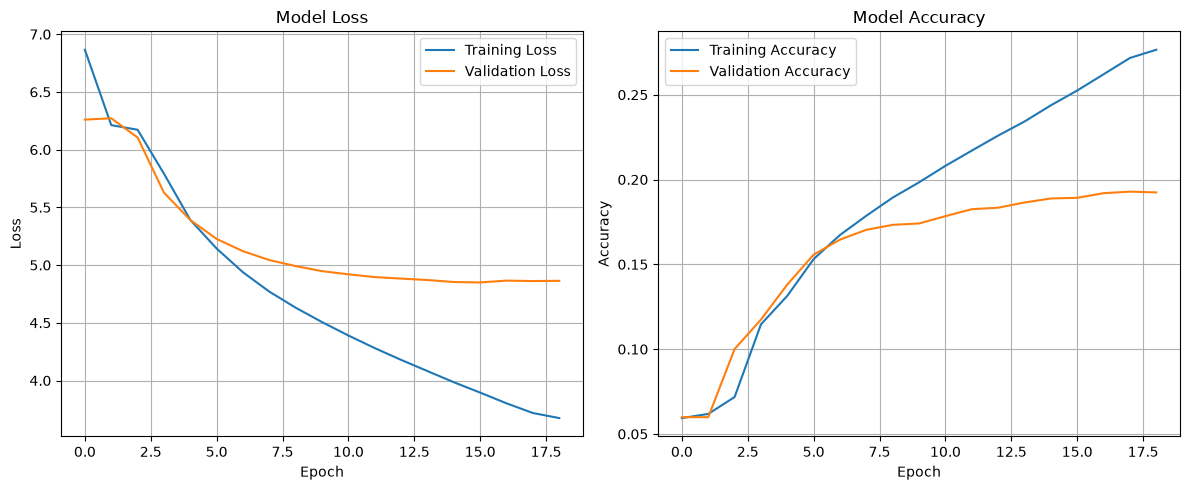

In [29]:
# Cell 7: Plot training metrics
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [30]:
def generate_text(model, sp, prompt, num_tokens=100, temperature=1.0):
    """
    Generate text autoregressively.

    Args:
        temperature: Controls randomness
            - Low (0.1-0.5): Focused, repetitive
            - Medium (0.7-1.0): Balanced
            - High (1.5+): Creative, chaotic
    """
    # Encode the prompt
    input_ids = sp.encode_as_ids(prompt)

    # Rest of your generation code stays the same...
    if len(input_ids) < seq_length:
        padding_length = seq_length - len(input_ids)
        input_ids = [0] * padding_length + input_ids
    else:
        padding_length = 0
        input_ids = input_ids[-seq_length:]

    # Generated tokens
    generated_ids = list(input_ids[padding_length:])

    # Generate text token by token
    for _ in range(num_tokens):
        x = np.array([input_ids])
        predictions = model.predict(x, verbose=0)[0]
        logits = predictions[-1]
        logits = logits / temperature
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / np.sum(exp_logits)
        next_token = np.random.choice(len(probs), p=probs)
        generated_ids.append(next_token)
        input_ids = input_ids[1:] + [next_token]

    # Decode the generated sequence
    generated_text = sp.decode(generated_ids)

    return generated_text
# Cell 10: Generate sample text
prompts = [
    "Phemius was still singing",
    "Telemachus took this speech",
    "Thus, then, did Ulysses wait",
    "Then Arete told her maids"
]

for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model, sp, prompt, num_tokens=100, temperature=0.5)
    print(generated)


Prompt: Phemius was still singing
Phemius was still singing, and my will not a man, but you have got back to the other, and my father's house of paying the house, and his father's estate. "I will tell you, for the gods, and tell you, but you have no more particularly to stay where you are in your father's son." "I will speak, and you will not think of your own house, and you will let us be- you? You have no more,' said, 'Ulysses

Prompt: Telemachus took this speech
Telemachus took this speech. I shall not one of the other of the women of them, and my father's son of Icarius, and how the gods who has been pleased to the suitors. I am no longer in my heart, and is a great man of Laertes, and the world is not to do so. I have no longer you, but you are your own country, who is not a man, for if you may do you always, for you will not be likely to me to your father's

Prompt: Thus, then, did Ulysses wait
Thus, then, did Ulysses wait for him, and they are not to the suitors. I am not the s

## Tulokset

### Aineisto

Valitsimme Homeroksen Odysseian, koska sen tyylin tunnistaa helposti. Tekstiä on 609 kilotavua. Sitä saa käyttää vapaasti, sillä kääntäjä Samuel Butler kuoli vuonna 1902.

### Mitä testasimme

Koulutimme neljä mallia ja muutimme niiden asetuksia.

<table>
<tr><th></th><th>Perusmalli</th><th>Pieni sanasto</th><th>Pieni malli</th><th>Suuri malli</th></tr>
<tr><td>vocab_size</td><td>10 000</td><td>2 000</td><td>10 000</td><td>10 000</td></tr>
<tr><td>seq_length</td><td>64</td><td>64</td><td>32</td><td>128</td></tr>
<tr><td>embed_dim</td><td>192</td><td>192</td><td>64</td><td>256</td></tr>
<tr><td>num_heads</td><td>4</td><td>4</td><td>2</td><td>8</td></tr>
<tr><td>ff_dim</td><td>384</td><td>384</td><td>128</td><td>512</td></tr>
<tr><td>num_layers</td><td>2</td><td>2</td><td>1</td><td>3</td></tr>
<tr><td>Parametreja</td><td>4,44 milj.</td><td>1,36 milj.</td><td>1,32 milj.</td><td>6,71 milj.</td></tr>
<tr><td>Koulutusaika noin</td><td>5 min</td><td>2 min</td><td>3 min</td><td>8 min</td></tr>
<tr><td>Tarkkuus (validointi)</td><td>18,9 %</td><td>21,8 %</td><td>18,4 %</td><td>19,5 %</td></tr>
<tr><td>Häviö merkkiä kohti</td><td>1,533</td><td>1,595</td><td>1,549</td><td>1,531</td></tr>
</table>

Ajat kuvaavat koulutusta vapaalla näytönohjaimella, sillä toinen ohjelma hidasti osaa ajoista.

### Mitä opimme

Valitsimme perusmallin. Siinä on upotuskerros, paikkakoodaus, kaksi transformerilohkoa ja ulostulokerros, yhteensä 4 444 048 parametria.

Suuri malli sai vain 0,002 pienemmän häviön, ja sen koulutus kesti 1,5 kertaa kauemmin. Ero on merkityksetön, koska perusmallin häviö vaihteli yhtä paljon kahden ajon välillä. Pieni malli sopii nopeaan koulutukseen, koska se hävisi perusmallille vain vähän.

Pieni sanasto oli nopein. Sen tarkkuus näyttää parhaalta, koska lyhyitä sanan paloja on helpompi arvata. Merkkiä kohti se oli silti huonoin.

### Lämpötila

Perusmalli jatkoi tekstiä "Tell me, O muse" näin.

<table>
<tr><th>Arvo</th><th>Malli kirjoitti</th><th>Havainto</th></tr>
<tr><td>0,2</td><td>and tell me, but I am not to be able</td><td>varovainen, toistaa itseään</td></tr>
<tr><td>0,7</td><td>I want to be. You must be always</td><td>paras tasapaino</td></tr>
<tr><td>1,0</td><td>formerly enough rejoicing, and caressed me great by us sorrow</td><td>kielioppi hajoaa</td></tr>
<tr><td>1,5</td><td>currents Helen, why I uproot however</td><td>sekava, keksii sanoja kuten thejol</td></tr>
</table>

Kokeilimme myös muita aloituksia. "Then Ulysses said" tuotti puhetta ja "The suitors were feasting" aloitti kerronnan.

### Miksi koulutus on hidasta

Malli aloittaa nollasta ja säätää 4,4 miljoonaa parametria yhä uudelleen. Aluksi yksi epookki kesti 126 sekuntia. Kun otimme mukaan vain joka kahdeksannen ikkunan, aika putosi 16 sekuntiin.

Yksi kirja ei riitä hyvään kielitaitoon. Edellisestä tokenista arvaaminen saa 17,6 % oikein ja mallimme 18,9 %. Siksi esikoulutetut mallit ovat arvokkaita. Ne ovat jo oppineet kielen valtavasta aineistosta.